# Assignment: Ensemble Methods (Feature Importance & AdaBoost.M1)

**Objective:** Implement Random Forest and AdaBoost.M1 for classification from scratch, handle corrupted data, and extract model interpretability metrics.

In [24]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
import warnings

# Formatting and warnings configuration
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.sans-serif": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11
})

# Set random seed for full reproducibility across experiments
np.random.seed(42)

## Part 1: Data Handling and Pre-processing

### Task 1.1: Load the Dataset
Load the Breast Cancer Wisconsin (Diagnostic) dataset from `sklearn.datasets` and extract the features (`X`), targets (`y`), and feature names.

In [25]:
# Load dataset and assign X, y, and feature_names
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target
feature_names = np.array(cancer.feature_names)

# Create a DataFrame for structured inspection and summary statistics
df_cancer = pd.DataFrame(data=X, columns=feature_names)
df_cancer['target'] = y

print("=" * 65)
print("Task 1.1: Breast Cancer Wisconsin (Diagnostic) Dataset Overview")
print("=" * 65)
print(f"Features matrix X shape: {X.shape} (Samples: {X.shape[0]}, Features: {X.shape[1]})")
print(f"Target vector y shape:    {y.shape}")
print(f"Target class names:       {cancer.target_names} -> 0: {cancer.target_names[0]}, 1: {cancer.target_names[1]}")
print("Class distribution:      ", {str(k): int(v) for k, v in zip(cancer.target_names, np.bincount(y))})
print("\nDataset Info Summary:")
df_cancer.info()

Task 1.1: Breast Cancer Wisconsin (Diagnostic) Dataset Overview
Features matrix X shape: (569, 30) (Samples: 569, Features: 30)
Target vector y shape:    (569,)
Target class names:       ['malignant' 'benign'] -> 0: malignant, 1: benign
Class distribution:       {'malignant': 212, 'benign': 357}

Dataset Info Summary:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    

In [26]:
print("\nFirst 5 rows of features:")
df_cancer.head()


First 5 rows of features:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


### Task 1.2: Inject Missing Values
Artificially corrupt the dataset by randomly masking exactly 5% of the elements in the feature matrix `X` as `np.nan`.

In [27]:
# Calculate 5% of total elements in X, randomly select indices, and set them to np.nan
X_corrupted = X.copy().astype(float)
total_elements = X_corrupted.size
n_missing = int(np.round(0.05 * total_elements))  # Exactly 5% of total elements

# Select random flat indices without replacement
rng = np.random.RandomState(42)
flat_missing_indices = rng.choice(total_elements, size=n_missing, replace=False)
row_idx, col_idx = np.unravel_index(flat_missing_indices, X_corrupted.shape)

# Inject np.nan at the selected locations
X_corrupted[row_idx, col_idx] = np.nan

# Verify the corruption
actual_missing = np.isnan(X_corrupted).sum()
percent_missing = (actual_missing / total_elements) * 100
affected_rows = np.isnan(X_corrupted).any(axis=1).sum()

In [28]:
print("=" * 65)
print("Task 1.2: Missing Value Injection Summary")
print("=" * 65)
print(f"Total elements in feature matrix:       {total_elements}")
print(f"Target missing elements (5%):           {n_missing}")
print(f"Actual missing elements injected:       {actual_missing}")
print(f"Missing percentage achieved:            {percent_missing:.2f}%")
print(f"Samples (rows) affected by missingness: {affected_rows} / {X_corrupted.shape[0]} ({(affected_rows / X_corrupted.shape[0]) * 100:.1f}%)")

Task 1.2: Missing Value Injection Summary
Total elements in feature matrix:       17070
Target missing elements (5%):           854
Actual missing elements injected:       854
Missing percentage achieved:            5.00%
Samples (rows) affected by missingness: 446 / 569 (78.4%)


### Task 1.3: Impute Missing Data
Initialize a `KNNImputer` (e.g., `n_neighbors=5`) and impute the missing values in your corrupted feature matrix.

In [29]:
# Initialize KNNImputer and fit_transform X
knn_imputer = KNNImputer(n_neighbors=5)
X_imputed = knn_imputer.fit_transform(X_corrupted)

# Verify no missing values remain
remaining_nans = np.isnan(X_imputed).sum()

print("=" * 65)
print("Task 1.3: KNN Imputation Summary")
print("=" * 65)
print(f"Missing elements before imputation: {actual_missing}")
print(f"Missing elements after imputation:  {remaining_nans}")
print(f"Imputed feature matrix shape:       {X_imputed.shape}")
assert remaining_nans == 0, "Error: Missing values remain after KNN imputation!"
print("Verification: All missing values successfully imputed via KNN (k=5).")

Task 1.3: KNN Imputation Summary
Missing elements before imputation: 854
Missing elements after imputation:  0
Imputed feature matrix shape:       (569, 30)
Verification: All missing values successfully imputed via KNN (k=5).


### Task 1.4: Stratified Train-Validation-Test Split
Perform a stratified split of the dataset into training (70%), validation (15%), and test (15%) sets. Ensure `stratify=y` is used.

In [30]:
# Perform stratified split (70% train, 15% validation, 15% test) using train_test_split twice

# Split 1: Separate 70% training set and 30% temporary set
X_train, X_temp, y_train, y_temp = train_test_split(
    X_imputed, y, test_size=0.30, random_state=42, stratify=y
)

# Split 2: Split the 30% temporary set equally into validation (15%) and test (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("=" * 65)
print("Task 1.4: Stratified Train-Validation-Test Split Verification")
print("=" * 65)
total_samples = len(y)
print(f"Training set:   {X_train.shape[0]} samples ({X_train.shape[0] / total_samples * 100:.1f}%)")
print(f"Validation set: {X_val.shape[0]} samples ({X_val.shape[0] / total_samples * 100:.1f}%)")
print(f"Test set:       {X_test.shape[0]} samples ({X_test.shape[0] / total_samples * 100:.1f}%)")

print("\nClass Distribution Across Splits (Demonstrating Stratification):")
split_df = pd.DataFrame({
    'Train Count': np.bincount(y_train),
    'Train Ratio': np.bincount(y_train) / len(y_train),
    'Val Count': np.bincount(y_val),
    'Val Ratio': np.bincount(y_val) / len(y_val),
    'Test Count': np.bincount(y_test),
    'Test Ratio': np.bincount(y_test) / len(y_test)
}, index=cancer.target_names)
split_df.round(4)

Task 1.4: Stratified Train-Validation-Test Split Verification
Training set:   398 samples (69.9%)
Validation set: 85 samples (14.9%)
Test set:       86 samples (15.1%)

Class Distribution Across Splits (Demonstrating Stratification):


,Train Count,Train Ratio,Val Count,Val Ratio,Test Count,Test Ratio
malignant,148,0.3719,32,0.3765,32,0.3721
benign,250,0.6281,53,0.6235,54,0.6279


## Part 2: Random Forest Classification from Scratch

### Task 2.1: Implement Decision Tree with Gini Tracking
Build a base `CustomDecisionTree` class. Your implementation must track the **Mean Decrease in Impurity (Gini)** for each feature used during a split to allow for Feature Importance calculation.

In [31]:
class CustomDecisionTree:
    """
    A binary Decision Tree Classifier built from scratch.
    Tracks the Mean Decrease in Impurity (Gini MDI) for each feature split.
    """
    def __init__(self, max_depth=5, max_features='sqrt'):
        self.max_depth = max_depth
        self.max_features = max_features
        self.feature_importances_ = None  # Array tracking Gini decrease for each feature
        self.tree_ = None                 # Internal tree representation
        self.n_features_ = None

    def _gini_impurity(self, y_node):
        """Calculate Gini Impurity for binary class labels {0, 1}."""
        n = len(y_node)
        if n == 0:
            return 0.0
        p1 = np.sum(y_node) / n
        p0 = 1.0 - p1
        return 1.0 - (p0 ** 2 + p1 ** 2)

    def _most_common_label(self, y_node):
        """Return the majority class label."""
        return np.bincount(y_node.astype(int)).argmax()

    def fit(self, X, y):
        """
        Build the decision tree from training dataset (X, y).
        Tracks Gini impurity decrease weighted by sample size for each split.
        """
        n_samples, self.n_features_ = X.shape
        self.feature_importances_ = np.zeros(self.n_features_, dtype=float)

        # Resolve number of features to evaluate per split
        if self.max_features == 'sqrt':
            self.max_features_num = max(1, int(np.sqrt(self.n_features_)))
        elif self.max_features == 'log2':
            self.max_features_num = max(1, int(np.log2(self.n_features_)))
        elif isinstance(self.max_features, (int, np.integer)):
            self.max_features_num = min(self.max_features, self.n_features_)
        else:
            self.max_features_num = self.n_features_

        # Grow tree starting from root
        self.tree_ = self._grow_tree(X, y, depth=0, total_samples=n_samples)

        # Normalize feature importances so they sum to 1 across the tree
        total_imp = np.sum(self.feature_importances_)
        if total_imp > 0:
            self.feature_importances_ = self.feature_importances_ / total_imp

        return self

    def _grow_tree(self, X, y, depth, total_samples):
        """Recursively grow tree nodes and record impurity decrease."""
        n_samples = len(y)

        # Stopping criteria: depth limit, pure leaf, or insufficient samples
        if depth >= self.max_depth or n_samples < 2 or len(np.unique(y)) == 1:
            return self._most_common_label(y)

        current_gini = self._gini_impurity(y)
        if current_gini == 0.0:
            return self._most_common_label(y)

        # Select random subset of feature indices without replacement
        feature_indices = np.random.choice(self.n_features_, size=self.max_features_num, replace=False)

        best_gain = -1.0
        best_feat = None
        best_thresh = None

        for feat in feature_indices:
            x_col = X[:, feat]
            sort_idx = np.argsort(x_col)
            x_sorted, y_sorted = x_col[sort_idx], y[sort_idx]

            # Only consider thresholds where consecutive class labels differ
            diff_mask = y_sorted[:-1] != y_sorted[1:]
            if not np.any(diff_mask):
                continue

            split_indices = np.where(diff_mask)[0]
            cum_y = np.cumsum(y_sorted)

            for sp in split_indices:
                n_left = sp + 1
                n_right = n_samples - n_left

                sum_left = cum_y[sp]
                sum_right = cum_y[-1] - sum_left

                p1_left = sum_left / n_left
                gini_left = 1.0 - (p1_left ** 2 + (1.0 - p1_left) ** 2)

                p1_right = sum_right / n_right
                gini_right = 1.0 - (p1_right ** 2 + (1.0 - p1_right) ** 2)

                split_gini = (n_left * gini_left + n_right * gini_right) / n_samples
                gain = current_gini - split_gini

                if gain > best_gain:
                    best_gain = gain
                    best_feat = feat
                    best_thresh = (x_sorted[sp] + x_sorted[sp + 1]) / 2.0

        # If no split produces positive impurity reduction, create leaf
        if best_gain <= 1e-7 or best_feat is None:
            return self._most_common_label(y)

        # Track Mean Decrease in Impurity (Gini) weighted by sample size:
        # delta_Gini * (n_samples_at_node / total_training_samples)
        node_weight = n_samples / total_samples
        self.feature_importances_[best_feat] += node_weight * best_gain

        # Partition data and recurse to child nodes
        left_mask = X[:, best_feat] <= best_thresh
        right_mask = ~left_mask

        left_subtree = self._grow_tree(X[left_mask], y[left_mask], depth + 1, total_samples)
        right_subtree = self._grow_tree(X[right_mask], y[right_mask], depth + 1, total_samples)

        return (best_feat, best_thresh, left_subtree, right_subtree)

    def predict(self, X):
        """Traverse the learned decision tree to predict class labels."""
        return np.array([self._predict_sample(sample, self.tree_) for sample in X], dtype=int)

    def _predict_sample(self, x, node):
        """Recursive sample traversal through internal nodes until a leaf label is reached."""
        if not isinstance(node, tuple):
            return node
        feat, thresh, left_child, right_child = node
        if x[feat] <= thresh:
            return self._predict_sample(x, left_child)
        else:
            return self._predict_sample(x, right_child)

### Task 2.2: Implement Custom Random Forest with OOB Error
Build the `CustomRandomForest` class. Implement bootstrap sampling, fit the base trees, calculate the Out-Of-Bag (OOB) error, and average the feature importances from all trees.

In [32]:
class CustomRandomForest:
    """
    A Random Forest Classifier built from scratch with:
    - Bootstrap aggregation (bagging)
    - Random feature subsampling per split
    - Out-of-Bag (OOB) error calculation
    - Ensembled Mean Decrease in Impurity (Gini) feature importances
    """
    def __init__(self, n_trees=100, max_depth=5, max_features='sqrt'):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.max_features = max_features
        self.trees = []
        self.feature_importances_ = None
        self.oob_error_ = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.trees = []
        
        # Matrix to accumulate Out-Of-Bag vote counts: shape (n_samples, 2)
        oob_votes = np.zeros((n_samples, 2), dtype=int)
        
        # Array to store feature importances from each individual tree
        all_tree_importances = np.zeros((self.n_trees, n_features), dtype=float)

        for i in range(self.n_trees):
            # Bootstrap sampling: draw n_samples with replacement
            bootstrap_indices = np.random.choice(n_samples, size=n_samples, replace=True)
            
            # Identify Out-Of-Bag (OOB) samples not included in this bootstrap sample
            in_bag_mask = np.zeros(n_samples, dtype=bool)
            in_bag_mask[bootstrap_indices] = True
            oob_indices = np.where(~in_bag_mask)[0]

            # Fit base CustomDecisionTree on bootstrap sample
            tree = CustomDecisionTree(max_depth=self.max_depth, max_features=self.max_features)
            tree.fit(X[bootstrap_indices], y[bootstrap_indices])
            self.trees.append(tree)

            # Store the tree's feature importances
            all_tree_importances[i] = tree.feature_importances_

            # Record predictions on OOB samples for OOB error calculation
            if len(oob_indices) > 0:
                oob_preds = tree.predict(X[oob_indices])
                for idx, pred in zip(oob_indices, oob_preds):
                    oob_votes[idx, int(pred)] += 1

        # Calculate Out-Of-Bag (OOB) Error:
        # Samples with at least one OOB vote receive majority OOB prediction
        has_oob_votes = oob_votes.sum(axis=1) > 0
        oob_predictions = np.zeros(n_samples, dtype=int)
        majority_class = np.bincount(y.astype(int)).argmax()
        
        oob_predictions[~has_oob_votes] = majority_class
        oob_predictions[has_oob_votes] = np.argmax(oob_votes[has_oob_votes], axis=1)
        
        self.oob_error_ = 1.0 - accuracy_score(y, oob_predictions)

        # Average the feature_importances_ across all base trees and normalize
        mean_importances = np.mean(all_tree_importances, axis=0)
        total_importance = np.sum(mean_importances)
        self.feature_importances_ = mean_importances / total_importance if total_importance > 0 else mean_importances

        return self

    def predict(self, X):
        """Aggregate predictions from all base trees using majority voting."""
        # Collect predictions from each tree: shape (n_trees, n_samples)
        tree_predictions = np.array([tree.predict(X) for tree in self.trees])
        
        # Majority voting (class with >= 50% of tree votes)
        majority_votes = (np.mean(tree_predictions, axis=0) >= 0.5).astype(int)
        return majority_votes

### Task 2.3: Train, Evaluate, and Plot Importances
Train your `CustomRandomForest` on the training set. Predict on the test set, print the accuracy and OOB error. Finally, create a horizontal bar chart displaying the top 10 most important features.

In [33]:
# Initialize and fit CustomRandomForest
custom_rf = CustomRandomForest(n_trees=100, max_depth=5, max_features='sqrt')
custom_rf.fit(X_train, y_train)

# Predict on test set
y_test_pred_rf = custom_rf.predict(X_test)

# Calculate test accuracy and OOB error
rf_test_accuracy = accuracy_score(y_test, y_test_pred_rf)
rf_oob_error = custom_rf.oob_error_

In [34]:
print("=" * 65)
print("Task 2.3: Custom Random Forest Evaluation Results")
print("=" * 65)
print(f"Test Accuracy:           {rf_test_accuracy:.4f} ({rf_test_accuracy * 100:.2f}%)")
print(f"Out-of-Bag (OOB) Error:  {rf_oob_error:.4f} ({rf_oob_error * 100:.2f}%)")
print(f"Out-of-Bag (OOB) Score:  {1.0 - rf_oob_error:.4f}")

# Classification Report
print("\nClassification Report (Custom Random Forest on Test Set):")
print(classification_report(y_test, y_test_pred_rf, target_names=cancer.target_names))

Task 2.3: Custom Random Forest Evaluation Results
Test Accuracy:           0.9070 (90.70%)
Out-of-Bag (OOB) Error:  0.0427 (4.27%)
Out-of-Bag (OOB) Score:  0.9573

Classification Report (Custom Random Forest on Test Set):
              precision    recall  f1-score   support

   malignant       0.93      0.81      0.87        32
      benign       0.90      0.96      0.93        54

    accuracy                           0.91        86
   macro avg       0.91      0.89      0.90        86
weighted avg       0.91      0.91      0.91        86



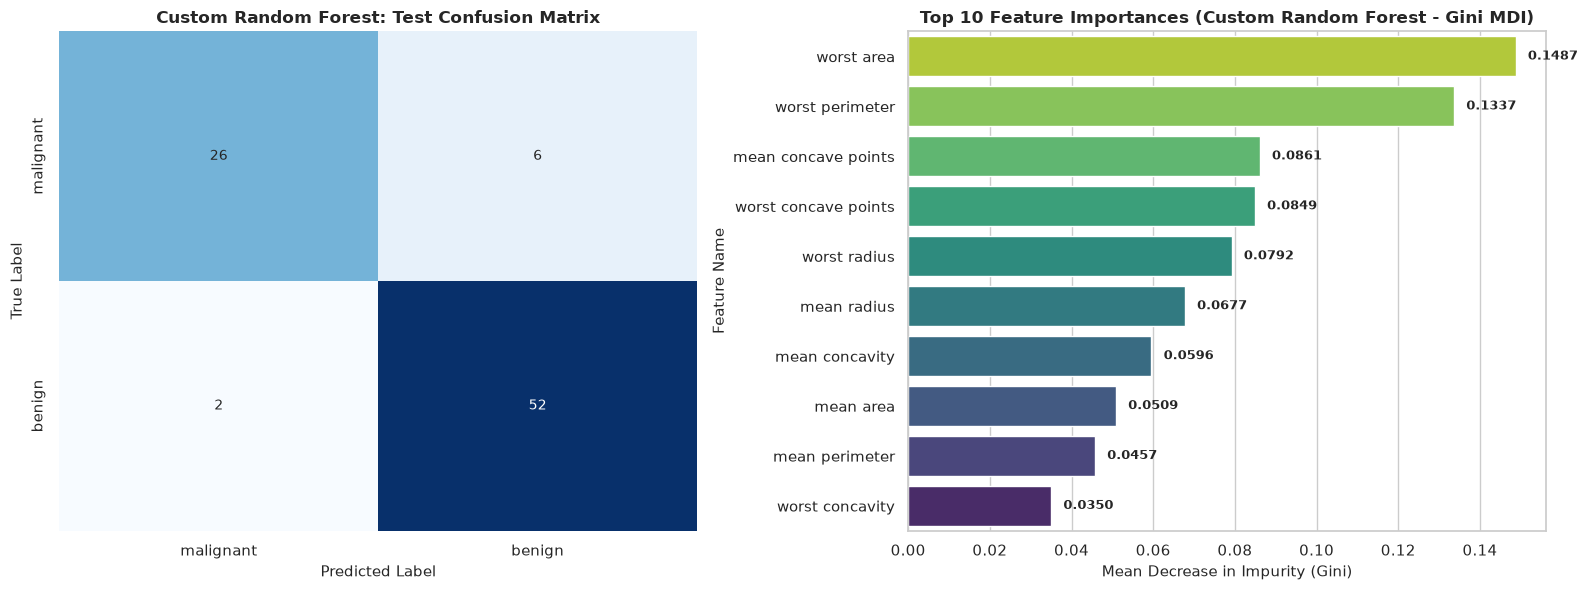

In [35]:
# Confusion Matrix and Feature Importance Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_rf = confusion_matrix(y_test, y_test_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=cancer.target_names, yticklabels=cancer.target_names)
axes[0].set_title('Custom Random Forest: Test Confusion Matrix', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].set_ylabel('True Label', fontsize=11)

# Plot Top 10 Feature Importances using feature_names
top10_indices = np.argsort(custom_rf.feature_importances_)[::-1][:10]
top10_features = feature_names[top10_indices]
top10_scores = custom_rf.feature_importances_[top10_indices]

palette = sns.color_palette("viridis_r", 10)
sns.barplot(x=top10_scores, y=top10_features, ax=axes[1], palette=palette)
axes[1].set_title('Top 10 Feature Importances (Custom Random Forest - Gini MDI)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Mean Decrease in Impurity (Gini)', fontsize=11)
axes[1].set_ylabel('Feature Name', fontsize=11)

# Annotate bars with numeric values
for i, v in enumerate(top10_scores):
    axes[1].text(v + 0.003, i, f"{v:.4f}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

In [36]:
# Display tabular summary of Top 10 Features
top10_df = pd.DataFrame({
    'Rank': range(1, 11),
    'Feature': top10_features,
    'Gini Importance': top10_scores
})
top10_df

,Rank,Feature,Gini Importance
0,1,worst area,0.148728
1,2,worst perimeter,0.133651
2,3,mean concave points,0.086072
3,4,worst concave points,0.084876
4,5,worst radius,0.079189
5,6,mean radius,0.067739
6,7,mean concavity,0.059558
7,8,mean area,0.050871
8,9,mean perimeter,0.045733
9,10,worst concavity,0.035005


## Part 3: AdaBoost.M1 from Scratch

### Task 3.1: Implement AdaBoost.M1 Classifier
Implement AdaBoost.M1 for binary classification. Your `fit` method must calculate validation accuracy at each boosting stage $m$ and store it in a list. *(Note: Ensure your `y` labels are mapped to `{-1, 1}` for the standard AdaBoost exponential loss math to work).*

In [37]:
class CustomAdaBoostM1:
    """
    AdaBoost.M1 Binary Classifier from scratch.
    Uses DecisionTreeClassifier stumps (max_depth=1) as base learners.
    Tracks validation accuracy at every boosting round m for learning curve analysis.
    Labels must be mapped to {-1, +1}.
    """
    def __init__(self, M=50):
        self.M = M
        self.models = []
        self.alphas = []
        self.val_accuracies = []

    def fit(self, X, y, X_val, y_val):
        """Fit M boosting rounds on (X, y) and evaluate ensemble validation accuracy at each stage."""
        n_samples = X.shape[0]
        # Initialize sample weights uniformly: w_i = 1 / N
        w = np.ones(n_samples, dtype=float) / n_samples
        
        self.models = []
        self.alphas = []
        self.val_accuracies = []

        # Vector to accumulate weighted votes on the validation set
        val_ensemble_votes = np.zeros(X_val.shape[0], dtype=float)

        for m in range(self.M):
            # 1. Fit weak learner (Decision Stump: max_depth=1) with sample weights w
            stump = DecisionTreeClassifier(max_depth=1, random_state=42 + m)
            stump.fit(X, y, sample_weight=w)

            # Predict on training samples
            y_pred_m = stump.predict(X)

            # 2. Calculate weighted error (err_m)
            incorrect = (y != y_pred_m).astype(float)
            err_m = np.sum(w * incorrect) / np.sum(w)

            # Numerical stability clipping
            err_m = np.clip(err_m, 1e-10, 1.0 - 1e-10)

            # In AdaBoost.M1, if error >= 0.5, weak classifier is no better than random guessing
            if err_m >= 0.5:
                print(f"Boosting stopped early at stage m={m+1}: weighted error {err_m:.4f} >= 0.5")
                break

            # 3. Calculate stage weight (alpha_m)
            alpha_m = 0.5 * np.log((1.0 - err_m) / err_m)

            # 4. Update and normalize sample weights (w)
            # Standard AdaBoost weight update: w_i <- w_i * exp(-alpha_m * y_i * h_m(x_i))
            w = w * np.exp(-alpha_m * y * y_pred_m)
            w = w / np.sum(w)  # Renormalize weights so sum(w) == 1

            # 5. Save the trained model and stage weight alpha
            self.models.append(stump)
            self.alphas.append(alpha_m)

            # 6. Predict on X_val using the ensemble built up to stage m
            val_pred_m = stump.predict(X_val)
            val_ensemble_votes += alpha_m * val_pred_m
            
            # Final ensemble prediction is sign of cumulative weighted votes
            current_stage_val_preds = np.sign(val_ensemble_votes)
            current_stage_val_preds[current_stage_val_preds == 0] = 1  # Break ties with +1
            
            # 7. Append current validation accuracy to self.val_accuracies
            stage_acc = accuracy_score(y_val, current_stage_val_preds)
            self.val_accuracies.append(stage_acc)

        return self

    def predict(self, X):
        """Aggregate predictions weighted by self.alphas. Return the sign() of the sum."""
        ensemble_votes = np.zeros(X.shape[0], dtype=float)
        for stump, alpha in zip(self.models, self.alphas):
            ensemble_votes += alpha * stump.predict(X)
        
        final_preds = np.sign(ensemble_votes)
        final_preds[final_preds == 0] = 1  # Break ties with +1
        return final_preds.astype(int)

### Task 3.2: Train, Plot Learning Curve, and Evaluate
Map your labels to `{-1, 1}`, fit the `CustomAdaBoostM1` model, and plot a line chart of **Validation Accuracy vs. Number of Weak Learners (M)**. Lastly, report the final Test Accuracy.

In [38]:
# Map labels from {0, 1} to {-1, 1} for standard AdaBoost exponential loss math
y_train_ada = np.where(y_train == 0, -1, 1)
y_val_ada = np.where(y_val == 0, -1, 1)
y_test_ada = np.where(y_test == 0, -1, 1)

# Initialize and fit CustomAdaBoostM1 with M=50
custom_adaboost = CustomAdaBoostM1(M=50)
custom_adaboost.fit(X_train, y_train_ada, X_val, y_val_ada)

# Predict on X_test and print Final Test Accuracy
y_test_pred_ada = custom_adaboost.predict(X_test)
ada_test_accuracy = accuracy_score(y_test_ada, y_test_pred_ada)

In [39]:
print("=" * 65)
print("Task 3.2: Custom AdaBoost.M1 Evaluation Results")
print("=" * 65)
print(f"Number of Boosting Stages (M):     {len(custom_adaboost.models)}")
print(f"Initial Validation Accuracy (m=1): {custom_adaboost.val_accuracies[0]:.4f}")
print(f"Peak Validation Accuracy:         {max(custom_adaboost.val_accuracies):.4f} (Stage m={np.argmax(custom_adaboost.val_accuracies) + 1})")
print(f"Final Validation Accuracy (m=50): {custom_adaboost.val_accuracies[-1]:.4f}")
print(f"Final Test Accuracy:              {ada_test_accuracy:.4f} ({ada_test_accuracy * 100:.2f}%)")

print("\nClassification Report (Custom AdaBoost.M1 on Test Set):")
print(classification_report(y_test_ada, y_test_pred_ada, target_names=['malignant (-1)', 'benign (+1)']))

Task 3.2: Custom AdaBoost.M1 Evaluation Results
Number of Boosting Stages (M):     50
Initial Validation Accuracy (m=1): 0.9059
Peak Validation Accuracy:         0.9882 (Stage m=17)
Final Validation Accuracy (m=50): 0.9647
Final Test Accuracy:              0.8837 (88.37%)

Classification Report (Custom AdaBoost.M1 on Test Set):
                precision    recall  f1-score   support

malignant (-1)       0.87      0.81      0.84        32
   benign (+1)       0.89      0.93      0.91        54

      accuracy                           0.88        86
     macro avg       0.88      0.87      0.87        86
  weighted avg       0.88      0.88      0.88        86



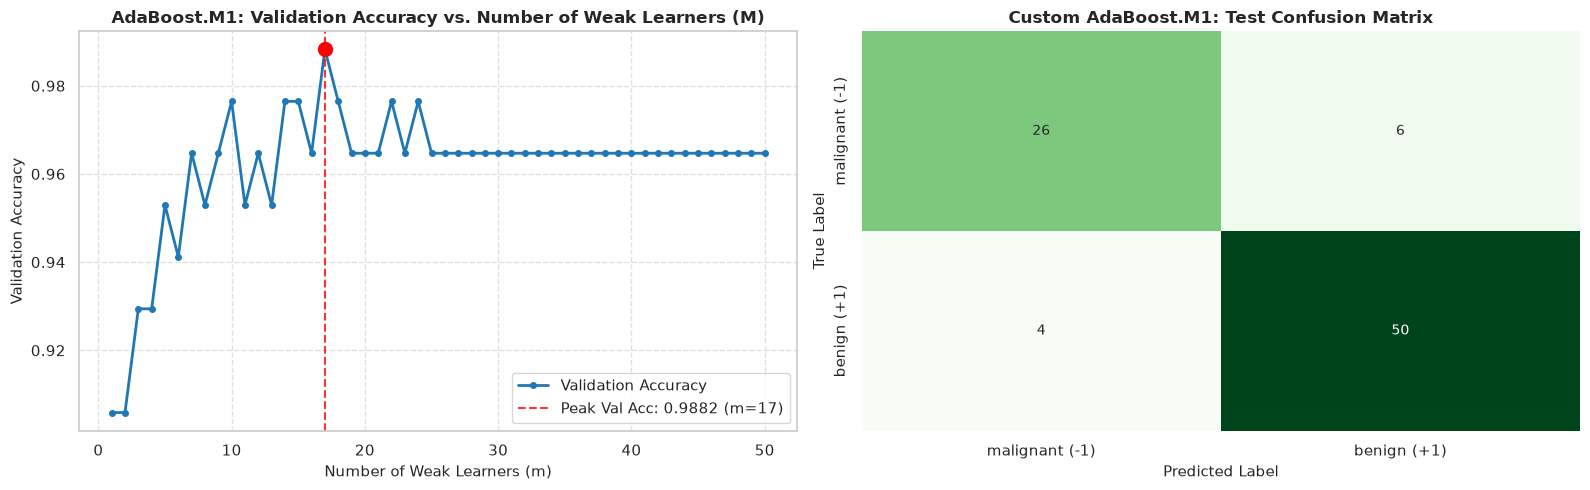

In [40]:
# Visualizations: Learning Curve & Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Validation Accuracy vs M Learning Curve
stages = range(1, len(custom_adaboost.val_accuracies) + 1)
axes[0].plot(stages, custom_adaboost.val_accuracies, marker='o', markersize=4,
             color='#1f77b4', linewidth=2, label='Validation Accuracy')
best_stage = np.argmax(custom_adaboost.val_accuracies) + 1
best_val = max(custom_adaboost.val_accuracies)
axes[0].axvline(best_stage, color='red', linestyle='--', alpha=0.8,
                label=f'Peak Val Acc: {best_val:.4f} (m={best_stage})')
axes[0].scatter([best_stage], [best_val], color='red', s=100, zorder=5)

axes[0].set_title('AdaBoost.M1: Validation Accuracy vs. Number of Weak Learners (M)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Weak Learners (m)', fontsize=11)
axes[0].set_ylabel('Validation Accuracy', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc='lower right', frameon=True)

# 2. Confusion Matrix Heatmap
cm_ada = confusion_matrix(y_test_ada, y_test_pred_ada)
sns.heatmap(cm_ada, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=['malignant (-1)', 'benign (+1)'],
            yticklabels=['malignant (-1)', 'benign (+1)'])
axes[1].set_title('Custom AdaBoost.M1: Test Confusion Matrix', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].set_ylabel('True Label', fontsize=11)

plt.tight_layout()
plt.show()

## Part 4: Scikit-Learn Comparison & Hyperparameter Tuning

### Task 4.1: Feature Importance Validation
Train `sklearn.ensemble.RandomForestClassifier` on the training data using the same hyperparameters. Extract its feature importances and print the Top 3 features. Print your custom RF's Top 3 features alongside it for comparison.

In [41]:
# Train sklearn RandomForestClassifier with the exact same hyperparameters
sklearn_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    max_features='sqrt',
    random_state=42,
    oob_score=True
)
sklearn_rf.fit(X_train, y_train)

# Evaluate sklearn RF on test set
y_test_pred_sk = sklearn_rf.predict(X_test)
sklearn_test_acc = accuracy_score(y_test, y_test_pred_sk)
sklearn_oob_err = 1.0 - sklearn_rf.oob_score_

# Extract Top 3 features from sklearn
top3_sk_indices = np.argsort(sklearn_rf.feature_importances_)[::-1][:3]
top3_sk_features = feature_names[top3_sk_indices]
top3_sk_importances = sklearn_rf.feature_importances_[top3_sk_indices]

# Extract Top 3 features from CustomRandomForest
top3_cust_indices = np.argsort(custom_rf.feature_importances_)[::-1][:3]
top3_cust_features = feature_names[top3_cust_indices]
top3_cust_importances = custom_rf.feature_importances_[top3_cust_indices]

In [42]:
print("=" * 65)
print("Task 4.1: Feature Importance Comparison (Top 3 Features)")
print("=" * 65)

comparison_df = pd.DataFrame({
    'Rank': [1, 2, 3],
    'Sklearn Feature': top3_sk_features,
    'Sklearn Importance': top3_sk_importances,
    'Custom RF Feature': top3_cust_features,
    'Custom RF Importance': top3_cust_importances
})
comparison_df.round(4)

Task 4.1: Feature Importance Comparison (Top 3 Features)


,Rank,Sklearn Feature,Sklearn Importance,Custom RF Feature,Custom RF Importance
0,1,worst concave points,0.1736,worst area,0.1487
1,2,worst area,0.1506,worst perimeter,0.1337
2,3,worst perimeter,0.0842,mean concave points,0.0861


In [43]:
print("\nModel Performance Comparison:")
perf_df = pd.DataFrame({
    'Model': ['Custom Random Forest', 'Scikit-Learn Random Forest'],
    'Test Accuracy': [rf_test_accuracy, sklearn_test_acc],
    'OOB Error': [rf_oob_error, sklearn_oob_err],
    'OOB Score': [1.0 - rf_oob_error, sklearn_rf.oob_score_]
})
perf_df.round(4)


Model Performance Comparison:


,Model,Test Accuracy,OOB Error,OOB Score
0,Custom Random Forest,0.907,0.0427,0.9573
1,Scikit-Learn Random Forest,0.907,0.0402,0.9598


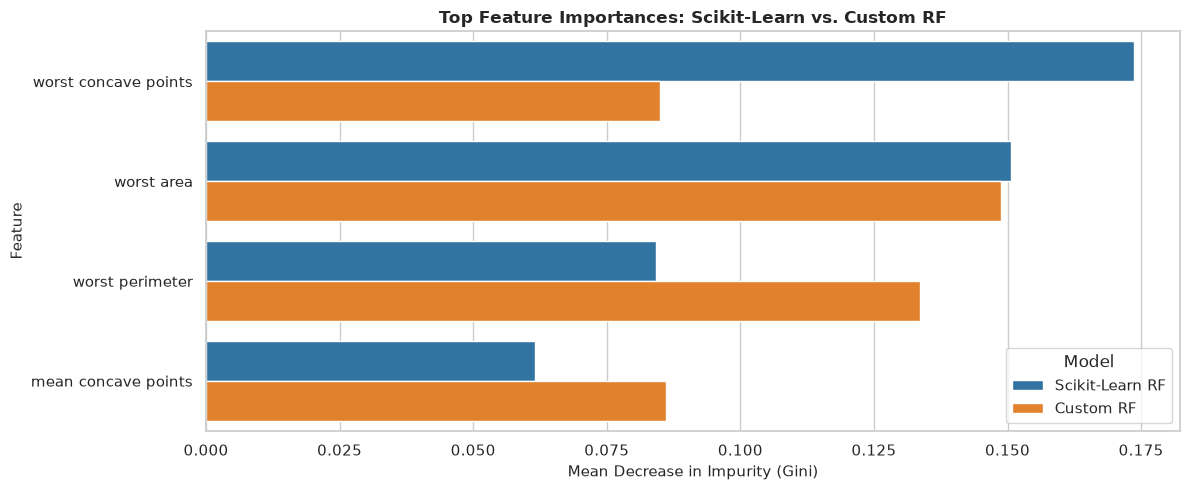

In [44]:
# Side-by-side visualization of Top 5 feature importances
fig, ax = plt.subplots(figsize=(12, 5))
top5_union = list(dict.fromkeys(list(top3_sk_features) + list(top3_cust_features)))
feat_df = pd.DataFrame({
    'Feature': top5_union * 2,
    'Importance': [sklearn_rf.feature_importances_[np.where(feature_names == f)[0][0]] for f in top5_union] +
                  [custom_rf.feature_importances_[np.where(feature_names == f)[0][0]] for f in top5_union],
    'Model': ['Scikit-Learn RF'] * len(top5_union) + ['Custom RF'] * len(top5_union)
})
sns.barplot(data=feat_df, x='Importance', y='Feature', hue='Model', palette=['#1f77b4', '#ff7f0e'], ax=ax)
ax.set_title('Top Feature Importances: Scikit-Learn vs. Custom RF', fontsize=12, fontweight='bold')
ax.set_xlabel('Mean Decrease in Impurity (Gini)', fontsize=11)
plt.tight_layout()
plt.show()

### Task 4.2: AdaBoost Grid Search
Define a parameter grid for `sklearn.ensemble.AdaBoostClassifier` (e.g., testing different `learning_rate` and `n_estimators` values). Run `GridSearchCV` on the training data and report the best parameters and final test accuracy.

In [45]:
# Define param_grid and initialize GridSearchCV with AdaBoostClassifier
param_grid = {
    'n_estimators': [20, 50, 100, 150, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0, 1.5]
}

ada_base = AdaBoostClassifier(random_state=42)
grid_search = GridSearchCV(
    estimator=ada_base,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy'
)

# Fit grid search on training data
grid_search.fit(X_train, y_train)

# Retrieve best parameters and score
best_params = grid_search.best_params_
best_cv_score = grid_search.best_score_
best_ada_model = grid_search.best_estimator_

# Evaluate on test set
y_test_pred_grid = best_ada_model.predict(X_test)
grid_test_accuracy = accuracy_score(y_test, y_test_pred_grid)

In [46]:
print("=" * 65)
print("Task 4.2: AdaBoost GridSearchCV Results")
print("=" * 65)
print(f"Best Hyperparameters:    {best_params}")
print(f"Best 5-Fold CV Accuracy: {best_cv_score:.4f} ({best_cv_score * 100:.2f}%)")
print(f"Final Test Accuracy:     {grid_test_accuracy:.4f} ({grid_test_accuracy * 100:.2f}%)")

print("\nClassification Report (Tuned AdaBoost on Test Set):")
print(classification_report(y_test, y_test_pred_grid, target_names=cancer.target_names))

# Comparison of Custom vs Tuned Scikit-Learn AdaBoost
print("\nAdaBoost Comparison:")
ada_comp_df = pd.DataFrame({
    'Model': ['Custom AdaBoost.M1 (M=50, lr=1.0)', f'Tuned Sklearn AdaBoost ({best_params})'],
    'Test Accuracy': [ada_test_accuracy, grid_test_accuracy]
})
ada_comp_df.round(4)

Task 4.2: AdaBoost GridSearchCV Results
Best Hyperparameters:    {'learning_rate': 0.5, 'n_estimators': 200}
Best 5-Fold CV Accuracy: 0.9750 (97.50%)
Final Test Accuracy:     0.9419 (94.19%)

Classification Report (Tuned AdaBoost on Test Set):
              precision    recall  f1-score   support

   malignant       0.97      0.88      0.92        32
      benign       0.93      0.98      0.95        54

    accuracy                           0.94        86
   macro avg       0.95      0.93      0.94        86
weighted avg       0.94      0.94      0.94        86


AdaBoost Comparison:


,Model,Test Accuracy
0,"Custom AdaBoost.M1 (M=50, lr=1.0)",0.8837
1,"Tuned Sklearn AdaBoost ({'learning_rate': 0.5,...",0.9419


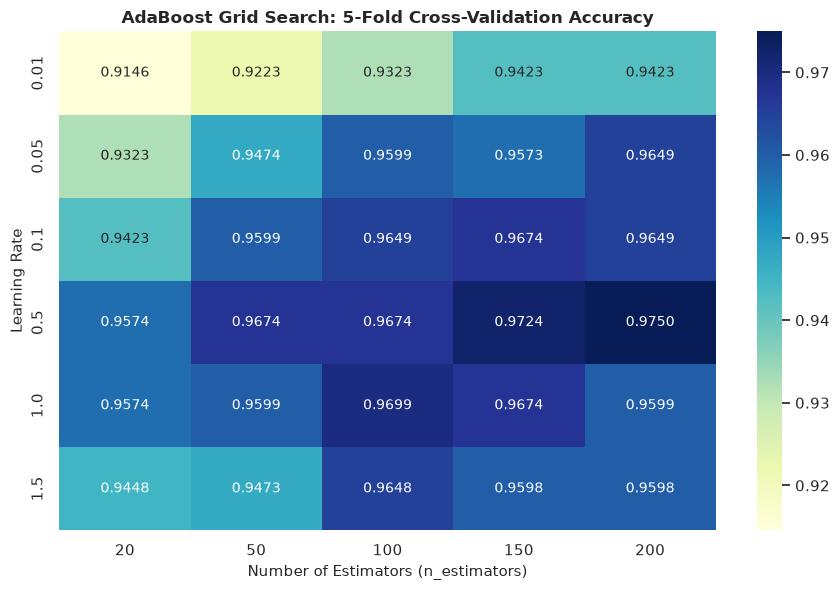

In [47]:
# Heatmap of Grid Search CV Mean Test Scores across n_estimators and learning_rate
cv_results_df = pd.DataFrame(grid_search.cv_results_)
scores_pivot = cv_results_df.pivot(index='param_learning_rate', columns='param_n_estimators', values='mean_test_score')

plt.figure(figsize=(9, 6))
sns.heatmap(scores_pivot, annot=True, fmt='.4f', cmap='YlGnBu')
plt.title('AdaBoost Grid Search: 5-Fold Cross-Validation Accuracy', fontsize=12, fontweight='bold')
plt.xlabel('Number of Estimators (n_estimators)', fontsize=11)
plt.ylabel('Learning Rate', fontsize=11)
plt.tight_layout()
plt.show()